In [35]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
import xgboost as xgb
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import accuracy_score, confusion_matrix,classification_report
from imblearn.over_sampling import SMOTE

In [135]:
df=pd.read_csv('final_raw_data.csv')

In [136]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1924 entries, 0 to 1923
Data columns (total 98 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Unnamed: 0                1924 non-null   int64  
 1   temperature_stat_0        1924 non-null   float64
 2   temperature_stat_3        1924 non-null   float64
 3   temperature_xt_jerk_1     1924 non-null   float64
 4   temperature_xt_jerk_2     1924 non-null   float64
 5   temperature_xt_jerk_6     1924 non-null   float64
 6   temperature_xt_jerk_7     1924 non-null   float64
 7   temperature_xt_jerk_9     1924 non-null   float64
 8   temperature_tm_dom_2      1924 non-null   float64
 9   temperature_tm_dom_4      1924 non-null   float64
 10  temperature_tm_dom_14     1924 non-null   float64
 11  temperature_tm_dom_15     1924 non-null   float64
 12  temperature_tm_dom_16     1924 non-null   float64
 13  temperature_tm_dom_18     1924 non-null   float64
 14  temperat

/var/folders/j2/mxbl1d3s7wqdbntq3mdbcgh00000gn/T/ipykernel_847/3958134968.py:2: FutureWarning: The default value of numeric_only in DataFrame.corr is deprecated. In a future version, it will default to False. Select only valid columns or specify the value of numeric_only to silence this warning.
  correlation_matrix = df.corr()


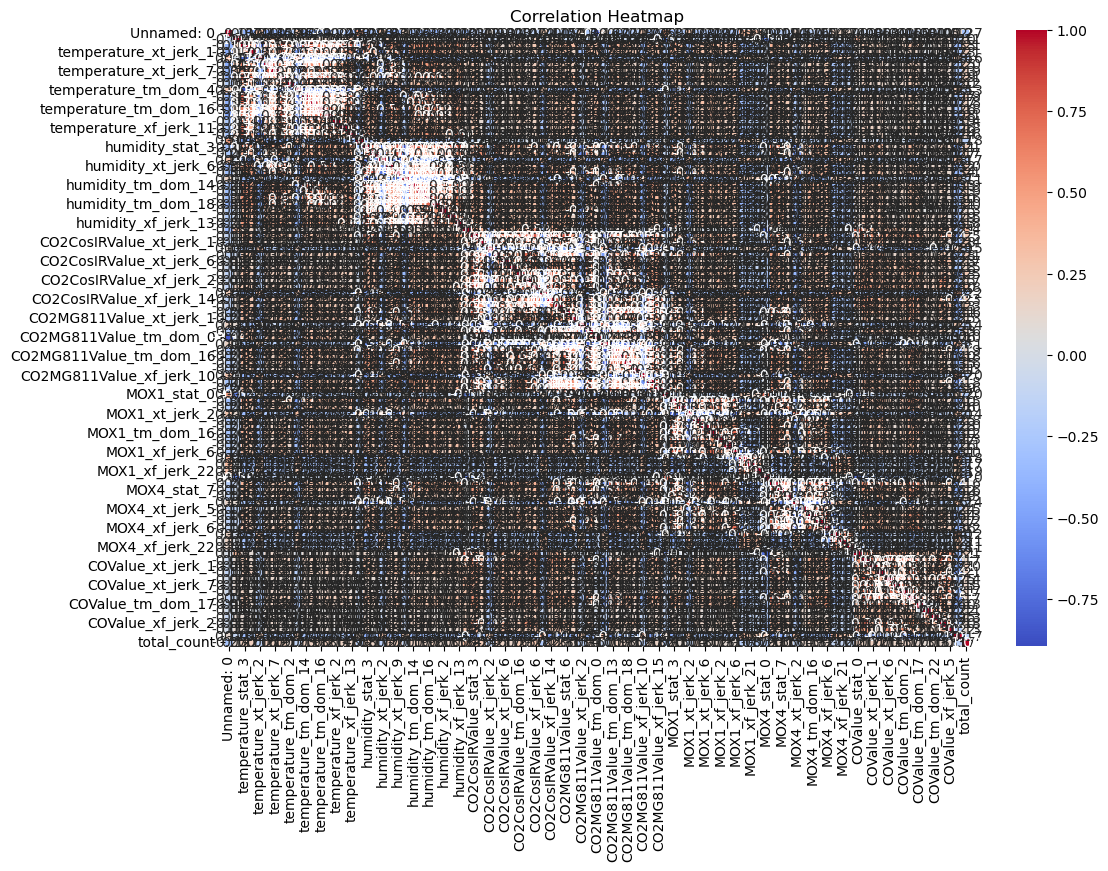

In [18]:
import seaborn as sns
correlation_matrix = df.corr()

# Create a heatmap
plt.figure(figsize=(12, 8))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt=".2f")
plt.title('Correlation Heatmap')
plt.show()

In [137]:
df['move_type'] = df['total_count'].apply(lambda x: 0 if x == 0 else 1 if 1 <= x <= 4 else 2)

In [138]:
df['move_type'].value_counts()

2    957
1    530
0    437
Name: move_type, dtype: int64

In [139]:
del df['Unnamed: 0']

In [423]:
#smote = SMOTE(sampling_strategy='auto', random_state=42)
#X_train, y_train = smote.fit_resample(X_train, y_train)

/var/folders/j2/mxbl1d3s7wqdbntq3mdbcgh00000gn/T/ipykernel_40670/3231737112.py:1: FutureWarning: The default value of numeric_only in DataFrame.corr is deprecated. In a future version, it will default to False. Select only valid columns or specify the value of numeric_only to silence this warning.
  correlation_matrix = df.corr()


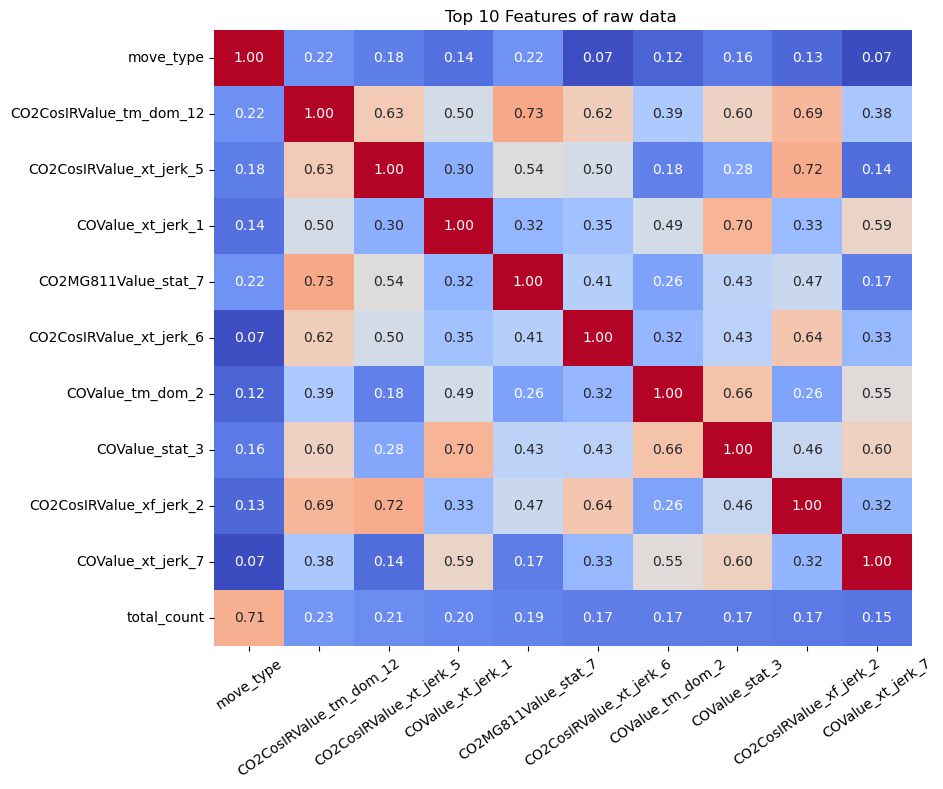

In [45]:
correlation_matrix = df.corr()
top_correlated_features = correlation_matrix['total_count'].sort_values(ascending=False)[1:11]

# Get the top correlated features names
top_correlated_features_names = top_correlated_features.index.tolist()

# Include 'total_count' in the list of top correlated features
top_correlated_features_names.append('total_count')

# Extract the correlation values for these features
top_correlation_matrix = df[top_correlated_features_names].corr()

# Drop duplicate 'total_count' column if it exists
if 'total_count' in top_correlation_matrix.columns:
    top_correlation_matrix.drop(columns=['total_count'], inplace=True)
# Create a heatmap
plt.figure(figsize=(9, 8))
heatmap=sns.heatmap(top_correlation_matrix, annot=True, cmap='coolwarm', fmt=".2f", cbar=False)
heatmap.set_xticklabels(heatmap.get_xticklabels(), rotation=35)

plt.title("Top 10 Features of raw data ")
plt.show()

In [140]:
drop_features = ['total_count','move_type','timestamp']
target_feature = 'move_type'

In [440]:
keep=['CO2CosIRValue_stat_0','temperature_xt_jerk_9','CO2MG811Value_tm_dom_0','humidity_stat_0','MOX1_stat_0','temperature_tm_dom_18','temperature_stat_0','temperature_xt_jerk_1','humidity_xt_jerk_9','temperature_xt_jerk_6','MOX1_stat_3','MOX1_tm_dom_16','humidity_stat_3','humidity_xt_jerk_2','temperature_tm_dom_16','temperature_xt_jerk_2','humidity_tm_dom_4','CO2CosIRValue_stat_3']

In [441]:
X=df[keep]

In [442]:
X

,CO2CosIRValue_stat_0,temperature_xt_jerk_9,CO2MG811Value_tm_dom_0,humidity_stat_0,MOX1_stat_0,temperature_tm_dom_18,temperature_stat_0,temperature_xt_jerk_1,humidity_xt_jerk_9,temperature_xt_jerk_6,MOX1_stat_3,MOX1_tm_dom_16,humidity_stat_3,humidity_xt_jerk_2,temperature_tm_dom_16,temperature_xt_jerk_2,humidity_tm_dom_4,CO2CosIRValue_stat_3
0,84.727778,1.813605,1262.610130,51.239833,530.872222,4.992788,19.699111,0.580000,7.546645,0.025,4.325219,190.145271,0.974251,-1.020000,19.629285,-0.680889,9.272061,4.295482
1,81.994444,1.269493,1269.269809,49.903167,427.705556,8.219864,20.202778,0.370000,6.732080,0.030,50.685325,3567.963362,1.064936,-0.900000,25.965631,-0.570000,9.271421,4.713326
2,85.977778,0.852427,1260.828281,50.692444,385.505556,8.083606,20.311944,0.631944,6.718433,0.030,23.892600,1717.811132,1.037522,-2.337556,21.871052,-0.220000,9.271790,2.930042
3,86.983240,1.150042,1257.883742,53.560223,409.351955,4.187562,19.517598,0.310000,3.971059,0.000,18.774737,487.317933,0.621436,-0.590000,7.670892,-0.842402,9.273426,1.010852
4,105.433333,1.147862,1232.111090,48.901778,464.738889,8.293930,24.203611,0.270000,7.668455,0.020,2.092776,61.171633,0.826778,-0.750000,24.303867,-0.756389,9.272689,1.460720
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1919,43.233333,0.140993,1057.821008,58.441167,528.961111,2.214626,20.275222,0.200000,0.826477,0.000,1.331156,69.090467,0.389594,-0.520000,13.172454,-0.314778,9.273960,0.873805
1920,42.883333,0.044746,1058.102375,58.252778,530.033333,1.327771,20.341500,0.231500,0.144371,0.000,0.957090,37.703437,0.253377,-0.207222,2.661725,-0.040000,9.274110,1.036755
1921,42.988889,0.057491,1057.757131,57.806222,530.455556,0.816131,20.396167,0.080000,0.252525,0.000,1.249629,48.929507,0.266046,-0.140000,2.645056,-0.103833,9.274106,1.225822
1922,43.650000,0.122300,1055.626657,57.908111,529.527778,2.673492,20.337611,0.090000,0.665958,0.010,1.404140,57.991448,0.294849,-0.200000,4.190032,-0.252389,9.274073,0.894890


In [443]:
X.shape

(1924, 18)

In [444]:
#X = df.drop(drop_features, axis=1)
y = df[target_feature]

In [148]:
X

,temperature_stat_0,temperature_stat_3,temperature_xt_jerk_1,temperature_xt_jerk_2,temperature_xt_jerk_6,temperature_xt_jerk_7,temperature_xt_jerk_9,temperature_tm_dom_2,temperature_tm_dom_4,temperature_tm_dom_14,...,COValue_xt_jerk_6,COValue_xt_jerk_7,COValue_tm_dom_2,COValue_tm_dom_10,COValue_tm_dom_17,COValue_tm_dom_21,COValue_tm_dom_22,COValue_xf_jerk_2,COValue_xf_jerk_5,COValue_xf_jerk_10
0,19.699111,0.395877,0.580000,-0.680889,0.025,0.015,1.813605,0.075971,9.271949,14.467027,...,0.0,0.0,0.419515,0.005434,22.387957,0.033149,0.055249,0.250748,2.393085,0.302777
1,20.202778,0.359069,0.370000,-0.570000,0.030,0.020,1.269493,0.069669,9.272376,8.106253,...,0.0,0.0,3.210310,0.011244,90.649493,0.011050,0.038674,0.731154,6.840019,0.236041
2,20.311944,0.292424,0.631944,-0.220000,0.030,0.015,0.852427,0.052578,9.273030,11.648553,...,0.0,0.0,0.248247,0.006910,48.361517,0.044199,0.027624,0.839343,1.296685,0.280246
3,19.517598,0.250620,0.310000,-0.842402,0.000,0.000,1.150042,0.190548,9.273343,6.705617,...,0.0,0.0,0.307312,0.004535,31.775584,0.049724,0.033149,1.284916,-0.063360,0.262780
4,24.203611,0.276077,0.270000,-0.756389,0.020,0.000,1.147862,0.024722,9.273553,7.538924,...,0.0,0.0,0.243901,0.003288,33.908122,0.033149,0.016575,0.226071,0.302181,0.259938
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1919,20.275222,0.147046,0.200000,-0.314778,0.000,0.000,0.140993,0.014572,9.273908,6.629005,...,0.0,0.0,0.504257,0.004249,36.621812,0.016575,0.044199,1.310984,0.298898,0.241917
1920,20.341500,0.175595,0.231500,-0.040000,0.000,0.000,0.044746,0.031217,9.273756,4.806146,...,0.0,0.0,1.320155,0.004627,48.911881,0.016575,0.049724,0.866868,-0.430699,0.260747
1921,20.396167,0.169853,0.080000,-0.103833,0.000,0.000,0.057491,0.034911,9.273787,1.182372,...,0.0,0.0,0.256020,0.003243,30.122879,0.033149,0.055249,0.227582,2.041977,0.267992
1922,20.337611,0.126663,0.090000,-0.252389,0.010,0.000,0.122300,0.044735,9.273994,4.190032,...,0.0,0.0,0.030426,0.003400,56.117396,0.027624,0.016575,1.174507,4.097968,0.279384


In [12]:
from sklearn.metrics import classification_report

Feature: CO2CosIRValue_stat_0 Score: 0.20747076598995307
Feature: temperature_xt_jerk_9 Score: 0.1689678238292336
Feature: CO2MG811Value_tm_dom_0 Score: 0.16461142565465003
Feature: humidity_stat_0 Score: 0.16077005964137392
Feature: MOX1_stat_0 Score: 0.15906220581263142
Feature: temperature_tm_dom_18 Score: 0.15378885647888207
Feature: temperature_stat_0 Score: 0.15284829349295137
Feature: temperature_xt_jerk_1 Score: 0.1462921123851748
Feature: humidity_xt_jerk_9 Score: 0.1411637209090273
Feature: temperature_xt_jerk_6 Score: 0.12809071982640408
Feature: MOX1_stat_3 Score: 0.12248405468861012
Feature: MOX1_tm_dom_16 Score: 0.11568684701222143
Feature: humidity_stat_3 Score: 0.11508783762450037
Feature: humidity_xt_jerk_2 Score: 0.11473974841041201
Feature: temperature_tm_dom_16 Score: 0.11374503693401117
Feature: temperature_xt_jerk_2 Score: 0.10826781949171682
Feature: humidity_tm_dom_4 Score: 0.10757033096200974
Feature: CO2CosIRValue_stat_3 Score: 0.10637631921193247
Feature: MOX

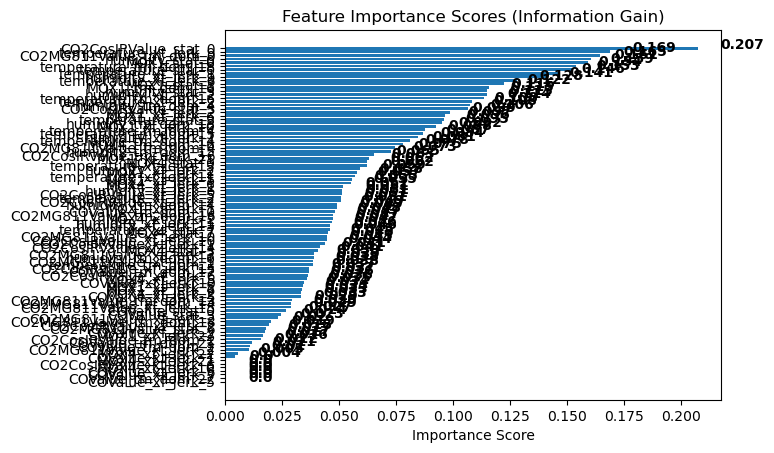

In [26]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_diabetes
from sklearn.feature_selection import mutual_info_regression


# Apply Information Gain
ig = mutual_info_regression(X, y)

# Create a dictionary of feature importance scores
feature_scores = {}
for i in range(len(X.columns)):
    feature_scores[X.columns[i]] = ig[i]
# Sort the features by importance score in descending order
sorted_features = sorted(feature_scores.items(), key=lambda x: x[1], reverse=True)

# Print the feature importance scores and the sorted features
for feature, score in sorted_features:
    print("Feature:", feature, "Score:", score)
# Plot a horizontal bar chart of the feature importance scores
fig, ax = plt.subplots()
y_pos = np.arange(len(sorted_features))
ax.barh(y_pos, [score for feature, score in sorted_features], align="center")
ax.set_yticks(y_pos)
ax.set_yticklabels([feature for feature, score in sorted_features])
ax.invert_yaxis()  # Labels read top-to-bottom
ax.set_xlabel("Importance Score")
ax.set_title("Feature Importance Scores (Information Gain)")

# Add importance scores as labels on the horizontal bar chart
for i, v in enumerate([score for feature, score in sorted_features]):
    ax.text(v + 0.01, i, str(round(v, 3)), color="black", fontweight="bold")
plt.show()

In [445]:
from sklearn.model_selection import train_test_split
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.25,random_state=747)

In [744]:
X_train['move_stat']=y_train.apply(lambda x: 0 if x == 0 else 1)

In [745]:
X_test['move_stat']=y_test.apply(lambda x: 0 if x == 0 else 1)

In [746]:
x_test=X_test.drop('move_stat', axis=1)

In [747]:
y_test1=X_test['move_stat']

In [748]:
x_train0=X_train.drop('move_stat', axis=1)
y_train0=X_train['move_stat']

In [749]:
smote = SMOTE(sampling_strategy='minority', random_state=42)
x_train0, y_train0 = smote.fit_resample(x_train0, y_train0)

In [750]:
nb_classifier = LogisticRegression(random_state=142)
nb_classifier.fit(x_train0, y_train0)

LogisticRegression(random_state=142)

In [752]:
x_train1=X_train[X_train['move_stat']==1]
x_train1=x_train1.drop('move_stat', axis=1)

In [753]:
y_train1=y_train[y_train!=0]

In [754]:
dt_classifier = RandomForestClassifier(n_estimators=300,max_depth=7)
dt_classifier.fit(x_train1, y_train1)

RandomForestClassifier(max_depth=7, n_estimators=300)

In [756]:
y_pred0=nb_classifier.predict(x_test)

In [757]:
y_pred0

array([0, 1, 1, 1, 1, 1, 0, 1, 1, 1, 1, 1, 1, 1, 0, 0, 0, 0, 1, 0, 1, 0,
       1, 1, 1, 0, 1, 0, 1, 1, 1, 1, 1, 0, 0, 1, 1, 1, 1, 0, 0, 1, 0, 1,
       1, 0, 1, 1, 1, 1, 0, 0, 0, 1, 0, 1, 1, 1, 1, 1, 0, 0, 0, 1, 1, 0,
       1, 1, 1, 0, 1, 1, 1, 0, 1, 0, 1, 1, 1, 1, 1, 1, 1, 0, 0, 0, 0, 1,
       1, 1, 0, 1, 1, 0, 0, 0, 1, 1, 1, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 0, 0, 1, 0, 0, 0, 0, 1, 0, 1, 1, 0, 0, 0, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 0, 1, 1, 1, 1, 0, 1, 0, 1, 0, 0, 1, 0, 0, 1,
       0, 1, 0, 1, 1, 1, 1, 0, 1, 0, 1, 1, 0, 1, 1, 1, 1, 1, 1, 0, 1, 1,
       1, 1, 1, 1, 0, 0, 1, 0, 1, 1, 0, 0, 1, 1, 1, 0, 0, 0, 1, 1, 1, 1,
       0, 1, 1, 1, 1, 0, 0, 1, 0, 1, 1, 1, 1, 1, 0, 1, 0, 1, 1, 1, 1, 0,
       1, 0, 1, 1, 0, 1, 0, 1, 0, 1, 0, 1, 1, 0, 1, 1, 1, 0, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 1, 1, 1, 1, 1, 0, 1, 0, 0, 1,
       1, 1, 1, 1, 1, 1, 0, 1, 1, 1, 0, 1, 0, 1, 1, 1, 1, 1, 0, 1, 1, 1,
       1, 1, 1, 1, 1, 0, 1, 0, 1, 1, 1, 0, 1, 0, 1,

In [758]:
print(accuracy_score(y_pred0,y_test1))

0.8577319587628865


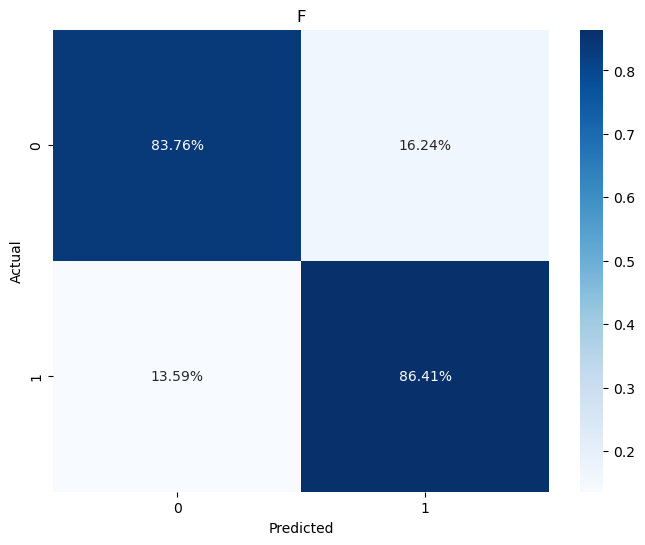

In [759]:
conf_matrix = confusion_matrix(y_test1, y_pred0)
conf_matrix_percentage = conf_matrix.astype('float') / conf_matrix.sum(axis=1)[:, np.newaxis]  # Calculate percentages

plt.figure(figsize=(8, 6))
sns.heatmap(conf_matrix_percentage, annot=True, fmt='.2%', cmap='Blues', xticklabels=[0,1], yticklabels=[0,1])
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('F')
plt.show()

In [760]:
x_test1=X_test[y_pred0==1]

In [761]:
x_test1=x_test1.drop('move_stat', axis=1)

In [762]:
x_test1

,CO2CosIRValue_stat_3,CO2CosIRValue_stat_9,CO2CosIRValue_xt_jerk_1,CO2CosIRValue_xt_jerk_5,CO2CosIRValue_xt_jerk_6,CO2CosIRValue_tm_dom_16,CO2CosIRValue_xf_jerk_2,CO2CosIRValue_xf_jerk_14,CO2CosIRValue_xf_jerk_15,COValue_stat_3,COValue_stat_9,COValue_xt_jerk_1,COValue_xt_jerk_5,COValue_xt_jerk_7,COValue_tm_dom_2
596,1.110956,2.201782e+06,2.594444,2.419154,0.0,58.323090,0.053506,5.602589,6.440144,1.151026,2.434782e+06,2.300000,4.506183,0.0,0.575359
446,1.069285,3.225168e+06,2.000000,3.830987,0.0,65.198806,0.813164,1.792824,5.731200,1.609622,3.042989e+06,2.016667,8.958018,0.0,0.622912
1276,3.400299,1.160614e+06,2.261111,4.013683,0.0,192.690109,0.258325,10.057056,7.935418,3.233738,2.090579e+06,3.738889,25.475245,0.0,0.664762
610,1.728183,1.943768e+06,2.000000,2.400308,0.0,47.002575,0.714410,4.612444,3.694519,1.943611,2.090140e+06,2.750000,11.930030,0.0,0.612431
652,5.473669,7.617551e+05,2.000000,65.356570,0.0,75.573503,0.669068,12.026770,2.493278,5.478133,1.471837e+06,4.300000,28.364483,0.0,1.493683
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1043,1.412650,2.638654e+06,3.000000,4.867819,0.0,76.135786,0.066667,3.666520,10.995344,4.784731,3.687939e+06,6.083333,61.109267,0.0,1.203585
1269,1.296925,1.674718e+06,1.000000,3.505229,0.0,112.705756,0.538985,4.038476,1.441765,1.405189,2.127147e+06,1.705556,6.977936,0.0,0.296378
198,4.950014,1.085288e+06,10.488889,58.396457,0.0,203.833636,0.488889,4.110212,28.372046,2.033936,1.289511e+06,2.000000,7.065487,0.0,0.867998
1122,1.383262,1.941388e+06,2.000000,3.070195,0.0,85.858557,0.785376,8.234774,2.381962,0.812181,1.950547e+06,2.094444,5.104772,0.0,0.410341


In [763]:
y_pred1=dt_classifier.predict(x_test1)

In [764]:
y_pred1

array([1, 1, 2, 2, 2, 2, 2, 2, 2, 1, 2, 2, 1, 2, 1, 2, 2, 2, 2, 2, 2, 2,
       1, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 1, 1,
       2, 2, 2, 2, 2, 1, 2, 2, 2, 2, 2, 2, 1, 2, 2, 1, 1, 1, 2, 1, 2, 2,
       2, 2, 2, 2, 1, 2, 2, 2, 2, 1, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2,
       2, 2, 2, 2, 2, 2, 2, 2, 1, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 1, 2, 1,
       2, 2, 1, 1, 2, 1, 2, 1, 2, 2, 2, 1, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2,
       2, 1, 2, 2, 2, 2, 2, 2, 2, 1, 2, 2, 2, 1, 2, 2, 2, 1, 2, 2, 2, 2,
       1, 2, 2, 1, 2, 1, 2, 2, 1, 2, 2, 2, 2, 1, 2, 2, 2, 2, 2, 2, 2, 2,
       2, 2, 2, 2, 2, 2, 2, 1, 2, 2, 2, 2, 2, 2, 2, 2, 1, 2, 1, 1, 2, 2,
       1, 2, 1, 2, 2, 1, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2,
       2, 2, 2, 2, 2, 2, 2, 2, 1, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 1, 2, 2,
       2, 1, 2, 2, 2, 1, 2, 2, 2, 2, 1, 2, 2, 1, 2, 2, 2, 2, 1, 2, 2, 1,
       2, 2, 2, 2, 2, 2, 2, 2, 2, 1, 2, 2, 2, 2, 2, 2, 2, 2, 2, 1, 1, 2,
       2, 2, 1, 2, 2, 2, 1, 2, 2, 2, 2, 2, 2, 2, 2,

In [765]:
y_pred0

array([0, 1, 1, 1, 1, 1, 0, 1, 1, 1, 1, 1, 1, 1, 0, 0, 0, 0, 1, 0, 1, 0,
       1, 1, 1, 0, 1, 0, 1, 1, 1, 1, 1, 0, 0, 1, 1, 1, 1, 0, 0, 1, 0, 1,
       1, 0, 1, 1, 1, 1, 0, 0, 0, 1, 0, 1, 1, 1, 1, 1, 0, 0, 0, 1, 1, 0,
       1, 1, 1, 0, 1, 1, 1, 0, 1, 0, 1, 1, 1, 1, 1, 1, 1, 0, 0, 0, 0, 1,
       1, 1, 0, 1, 1, 0, 0, 0, 1, 1, 1, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 0, 0, 1, 0, 0, 0, 0, 1, 0, 1, 1, 0, 0, 0, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 0, 1, 1, 1, 1, 0, 1, 0, 1, 0, 0, 1, 0, 0, 1,
       0, 1, 0, 1, 1, 1, 1, 0, 1, 0, 1, 1, 0, 1, 1, 1, 1, 1, 1, 0, 1, 1,
       1, 1, 1, 1, 0, 0, 1, 0, 1, 1, 0, 0, 1, 1, 1, 0, 0, 0, 1, 1, 1, 1,
       0, 1, 1, 1, 1, 0, 0, 1, 0, 1, 1, 1, 1, 1, 0, 1, 0, 1, 1, 1, 1, 0,
       1, 0, 1, 1, 0, 1, 0, 1, 0, 1, 0, 1, 1, 0, 1, 1, 1, 0, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 1, 1, 1, 1, 1, 0, 1, 0, 0, 1,
       1, 1, 1, 1, 1, 1, 0, 1, 1, 1, 0, 1, 0, 1, 1, 1, 1, 1, 0, 1, 1, 1,
       1, 1, 1, 1, 1, 0, 1, 0, 1, 1, 1, 0, 1, 0, 1,

In [766]:
y_test2=y_test[y_pred0==1]

In [767]:
y_test2.value_counts()

2    216
1    102
0     19
Name: move_type, dtype: int64

In [768]:
print(accuracy_score(y_pred1,y_test2))

0.7151335311572701


In [20]:
conf_matrix = confusion_matrix(y_test2, y_pred1)
conf_matrix_percentage = conf_matrix.astype('float') / conf_matrix.sum(axis=1)[:, np.newaxis]  # Calculate percentages

plt.figure(figsize=(8, 6))
sns.heatmap(conf_matrix_percentage, annot=True, fmt='.2%', cmap='coolwarm', xticklabels=[0,1,2], yticklabels=[0,1,2])
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('F')
plt.show()

NameError: name 'y_test2' is not defined

In [770]:
y_pred0[y_pred0==1]=y_pred1

In [771]:
print(accuracy_score(y_pred0,y_test))

0.6989690721649484


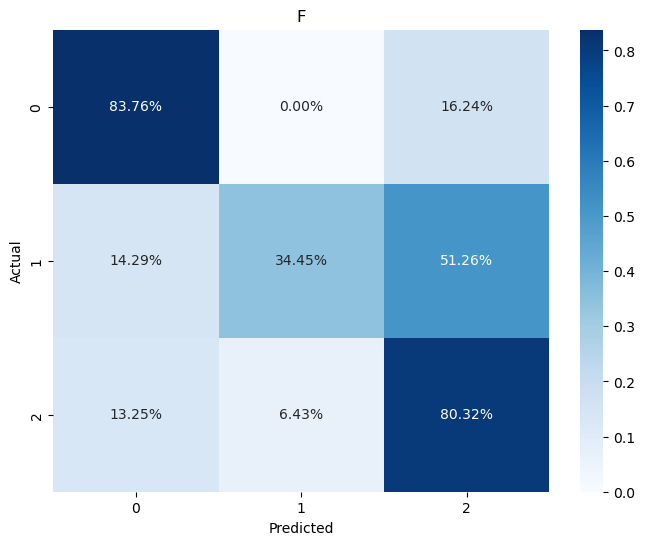

In [773]:
conf_matrix = confusion_matrix(y_test, y_pred0)
conf_matrix_percentage = conf_matrix.astype('float') / conf_matrix.sum(axis=1)[:, np.newaxis]  # Calculate percentages

plt.figure(figsize=(8, 6))
sns.heatmap(conf_matrix_percentage, annot=True, fmt='.2%', cmap='Blues', xticklabels=[0,1,2], yticklabels=[0,1,2])
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('F')
plt.show()

# Logistic classifier

In [531]:
model1 = LogisticRegression(max_iter=1000,multi_class='ovr', random_state=2,C=10,penalty='l2',solver='newton-cg')
model1.fit(X_train,y_train)
y_pred=model1.predict(X_test)

/Users/sayemahmed/anaconda3/lib/python3.11/site-packages/scipy/optimize/_linesearch.py:457: LineSearchWarning: The line search algorithm did not converge
  warn('The line search algorithm did not converge', LineSearchWarning)
/Users/sayemahmed/anaconda3/lib/python3.11/site-packages/scipy/optimize/_linesearch.py:306: LineSearchWarning: The line search algorithm did not converge
  warn('The line search algorithm did not converge', LineSearchWarning)


In [532]:
accuracy = accuracy_score(y_test, y_pred)
report = classification_report(y_test, y_pred)

print(f"Accuracy: {accuracy:.2f}")
print("Classification Report:\n", report)

Accuracy: 0.73
Classification Report:
               precision    recall  f1-score   support

           0       0.78      0.88      0.83       111
           1       0.63      0.39      0.48       116
           2       0.74      0.83      0.78       254

    accuracy                           0.73       481
   macro avg       0.72      0.70      0.70       481
weighted avg       0.72      0.73      0.72       481



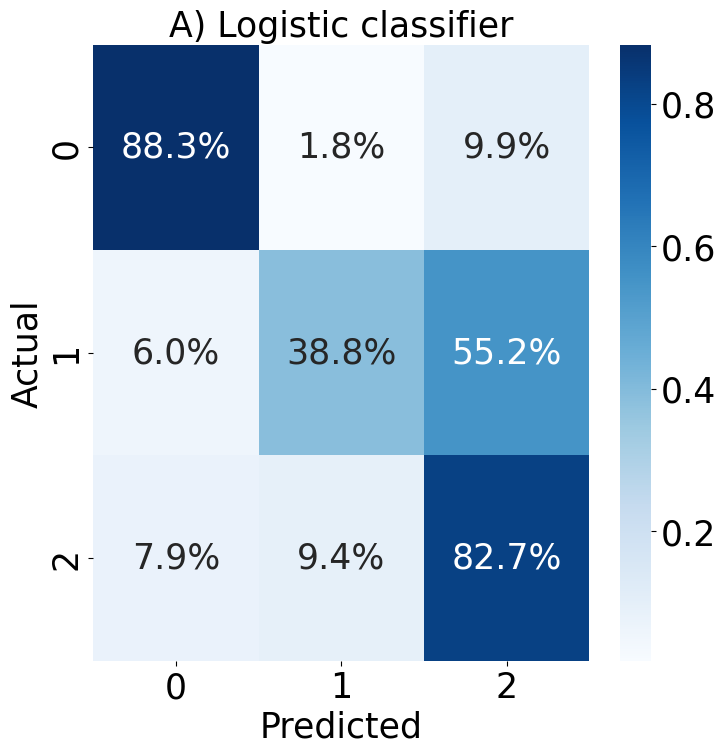

In [533]:
conf_matrix = confusion_matrix(y_test, y_pred)
conf_matrix_percentage = conf_matrix.astype('float') / conf_matrix.sum(axis=1)[:, np.newaxis]  # Calculate percentages

plt.figure(figsize=(8, 8))
heatmap=sns.heatmap(conf_matrix_percentage, annot=True, fmt='.1%', cmap='Blues', xticklabels=[0,1,2], yticklabels=[0,1,2],annot_kws={"size": 25})
plt.xticks(fontsize=25)
plt.yticks(fontsize=25)
plt.xlabel('Predicted',fontsize=25)
plt.ylabel('Actual',fontsize=25)
plt.title('A) Logistic classifier',fontsize=25)
cbar = heatmap.collections[0].colorbar
cbar.ax.tick_params(labelsize=25)
#cbar.set_ticks(np.linspace(0, .81, num=9))  # Set custom tick locations
#cbar.set_ticklabels(['0.0', '0.1', '0.2', '0.3', '0.4', '0.5', '0.6', '0.7', '0.8']) 
plt.show()

# Decision Tree

In [550]:
model2 = DecisionTreeClassifier(max_depth=5,splitter='best')
model2.fit(X_train,y_train)
y_pred=model2.predict(X_test)

In [551]:
accuracy = accuracy_score(y_test, y_pred)
report = classification_report(y_test, y_pred)

print(f"Accuracy: {accuracy:.2f}")
print("Classification Report:\n", report)

Accuracy: 0.72
Classification Report:
               precision    recall  f1-score   support

           0       0.81      0.82      0.82       111
           1       0.54      0.43      0.48       116
           2       0.74      0.80      0.77       254

    accuracy                           0.72       481
   macro avg       0.70      0.68      0.69       481
weighted avg       0.71      0.72      0.71       481



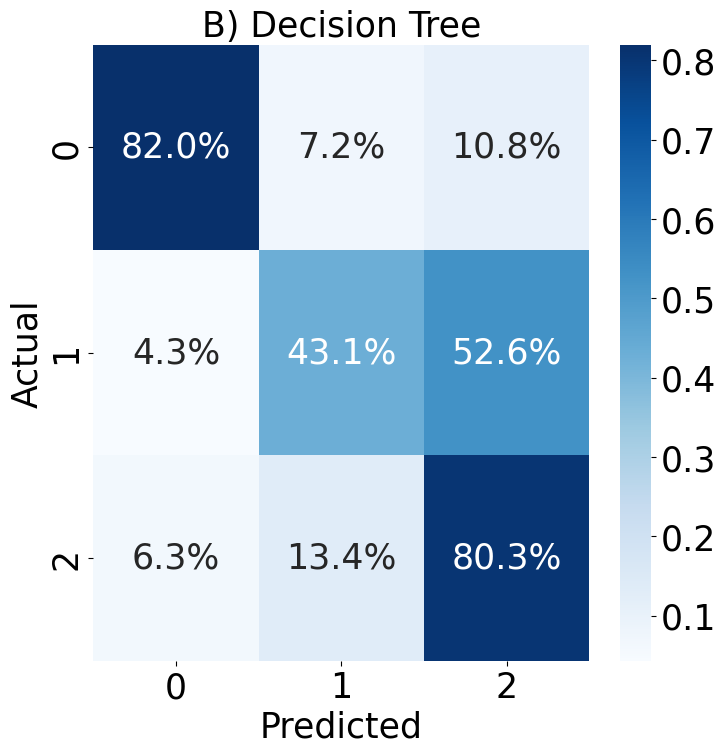

In [552]:
conf_matrix = confusion_matrix(y_test, y_pred)
conf_matrix_percentage = conf_matrix.astype('float') / conf_matrix.sum(axis=1)[:, np.newaxis]  # Calculate percentages

plt.figure(figsize=(8, 8))
heatmap=sns.heatmap(conf_matrix_percentage, annot=True, fmt='.1%', cmap='Blues', xticklabels=[0,1,2], yticklabels=[0,1,2],annot_kws={"size": 25})
plt.xticks(fontsize=25)
plt.yticks(fontsize=25)
plt.xlabel('Predicted',fontsize=25)
plt.ylabel('Actual',fontsize=25)
plt.title('B) Decision Tree',fontsize=25)
cbar = heatmap.collections[0].colorbar
cbar.ax.tick_params(labelsize=25)
plt.show()

# Random Forest

In [558]:
model3 = RandomForestClassifier(n_estimators=250,max_depth=5)
model3.fit(X_train, y_train)

# Make predictions
y_pred = model3.predict(X_test)

# Evaluate accuracy
accuracy = accuracy_score(y_test, y_pred)
print(f'Accuracy: {accuracy}')
report = classification_report(y_test, y_pred)
print("Classification Report:\n", report)

Accuracy: 0.7754677754677755
Classification Report:
               precision    recall  f1-score   support

           0       0.88      0.83      0.85       111
           1       0.74      0.47      0.58       116
           2       0.75      0.89      0.81       254

    accuracy                           0.78       481
   macro avg       0.79      0.73      0.75       481
weighted avg       0.78      0.78      0.77       481



In [559]:
y_pred_train = model3.predict(X_train)
accuracy = accuracy_score(y_train, y_pred_train)
print(f'Accuracy: {accuracy}')

Accuracy: 0.7387387387387387


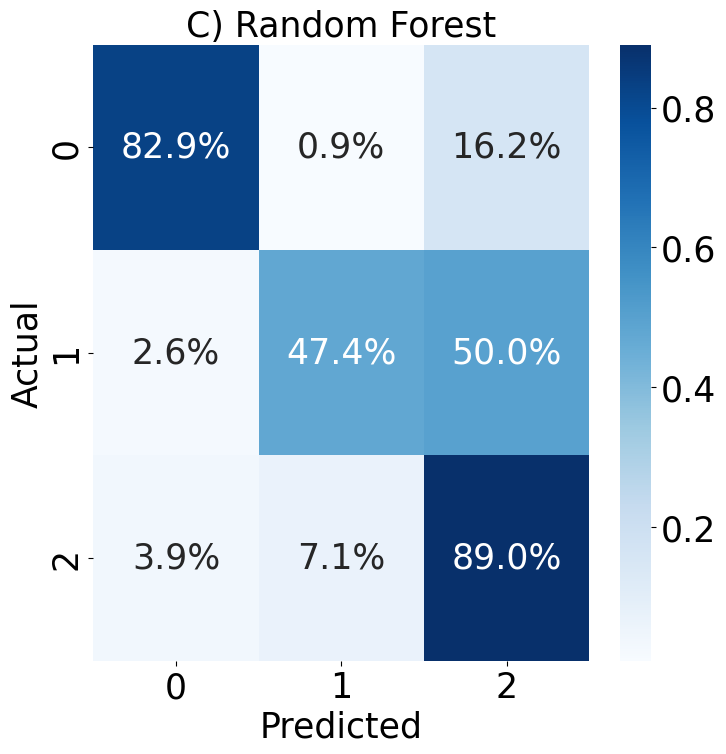

In [560]:
conf_matrix = confusion_matrix(y_test, y_pred)
conf_matrix_percentage = conf_matrix.astype('float') / conf_matrix.sum(axis=1)[:, np.newaxis]  # Calculate percentages

plt.figure(figsize=(8, 8))
heatmap=sns.heatmap(conf_matrix_percentage, annot=True, fmt='.1%', cmap='Blues', xticklabels=[0,1,2], yticklabels=[0,1,2],annot_kws={"size": 25})
plt.xticks(fontsize=25)
plt.yticks(fontsize=25)
plt.xlabel('Predicted',fontsize=25)
plt.ylabel('Actual',fontsize=25)
plt.title('C) Random Forest',fontsize=25)
cbar = heatmap.collections[0].colorbar
cbar.ax.tick_params(labelsize=25)
plt.show()

# XGboost

In [561]:
model4=xgb.XGBClassifier(objective='multi:softmax',learning_rate=0.01,max_depth=3,n_estimators=300,num_class=len(set(y)))
model4.fit(X_train,y_train)
y_pred=model4.predict(X_test)
accuracy = accuracy_score(y_test, y_pred)
report = classification_report(y_test, y_pred)
print(f"Accuracy: {accuracy:.3f}")
print("Classification Report:\n", report)

Accuracy: 0.763
Classification Report:
               precision    recall  f1-score   support

           0       0.81      0.86      0.84       111
           1       0.74      0.46      0.56       116
           2       0.75      0.86      0.80       254

    accuracy                           0.76       481
   macro avg       0.77      0.73      0.73       481
weighted avg       0.76      0.76      0.75       481



In [434]:
scores=[]
for i in range(1000):
    X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.25,random_state=i)
    model4=xgb.XGBClassifier(objective='multi:softmax',learning_rate=0.01,max_depth=3,n_estimators=450,num_class=len(set(y)))
    model4.fit(X_train,y_train)
    y_pred=model4.predict(X_test)
    scores.append(accuracy_score(y_test, y_pred))

In [435]:
np.argmax(scores)

747

In [436]:
top_5_indices = np.argsort(scores)[-5:][::-1]

print("Indices of top 5 scores:", top_5_indices)
print("Top 5 scores:", [scores[i] for i in top_5_indices])

Indices of top 5 scores: [747 345 322 836 613]
Top 5 scores: [0.760914760914761, 0.7546777546777547, 0.7546777546777547, 0.7525987525987526, 0.7505197505197505]


In [309]:
scores

[0.6923076923076923,
 0.735966735966736,
 0.7047817047817048,
 0.7234927234927235,
 0.7234927234927235,
 0.6943866943866944,
 0.7234927234927235,
 0.7027027027027027,
 0.7047817047817048,
 0.6798336798336798,
 0.7006237006237006,
 0.7193347193347194,
 0.7338877338877339,
 0.6902286902286903,
 0.6923076923076923,
 0.683991683991684,
 0.7193347193347194,
 0.6715176715176715,
 0.7193347193347194,
 0.7214137214137214,
 0.6881496881496881,
 0.6902286902286903,
 0.7068607068607069,
 0.7130977130977131,
 0.6985446985446986,
 0.735966735966736,
 0.6985446985446986,
 0.7068607068607069,
 0.7193347193347194,
 0.683991683991684,
 0.6694386694386695,
 0.7130977130977131,
 0.7172557172557172,
 0.6798336798336798,
 0.6652806652806653,
 0.7172557172557172,
 0.683991683991684,
 0.7006237006237006,
 0.7255717255717256,
 0.7110187110187111,
 0.7047817047817048,
 0.6881496881496881,
 0.7068607068607069,
 0.6985446985446986,
 0.6964656964656964,
 0.6943866943866944,
 0.7401247401247402,
 0.711018711018711

In [310]:
scores[np.argmax(scores)]

0.760914760914761

In [298]:
scores.sort(reverse = True)

print(scores)

[0.760914760914761, 0.7546777546777547, 0.7505197505197505, 0.7505197505197505, 0.7484407484407485, 0.7484407484407485, 0.7484407484407485, 0.7484407484407485, 0.7463617463617463, 0.7463617463617463, 0.7463617463617463, 0.7442827442827443, 0.7442827442827443, 0.7442827442827443, 0.7442827442827443, 0.7442827442827443, 0.7442827442827443, 0.7442827442827443, 0.7442827442827443, 0.7422037422037422, 0.7422037422037422, 0.7422037422037422, 0.7422037422037422, 0.7422037422037422, 0.7422037422037422, 0.7401247401247402, 0.7401247401247402, 0.7401247401247402, 0.7401247401247402, 0.7401247401247402, 0.7401247401247402, 0.7401247401247402, 0.7401247401247402, 0.7401247401247402, 0.7401247401247402, 0.7401247401247402, 0.738045738045738, 0.738045738045738, 0.738045738045738, 0.738045738045738, 0.738045738045738, 0.738045738045738, 0.738045738045738, 0.738045738045738, 0.738045738045738, 0.738045738045738, 0.735966735966736, 0.735966735966736, 0.735966735966736, 0.735966735966736, 0.735966735966

In [518]:
y_pred_train = model4.predict(X_train)
accuracy = accuracy_score(y_train, y_pred_train)
print(f'Accuracy: {accuracy}')

Accuracy: 0.7394317394317395


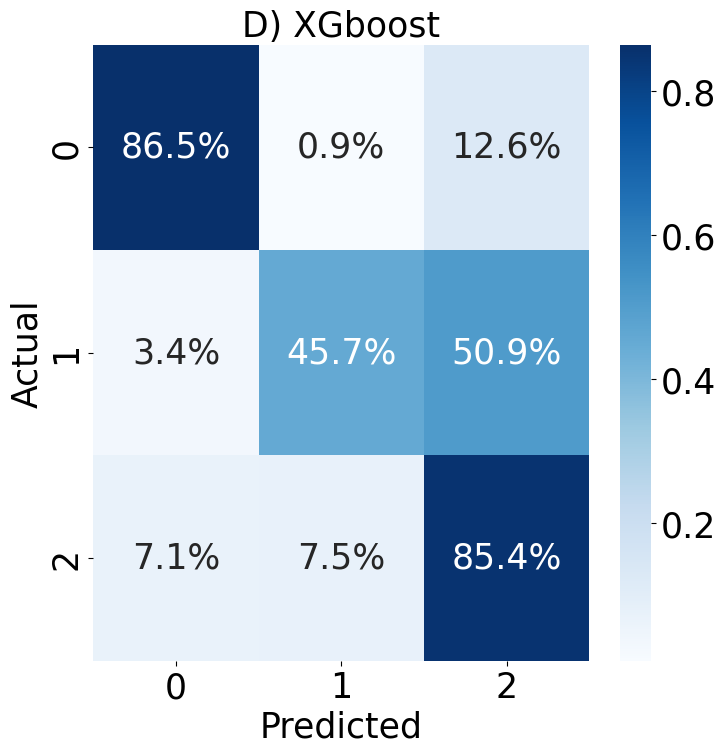

In [519]:
conf_matrix = confusion_matrix(y_test, y_pred)
conf_matrix_percentage = conf_matrix.astype('float') / conf_matrix.sum(axis=1)[:, np.newaxis]  # Calculate percentages

plt.figure(figsize=(8, 8))
heatmap=sns.heatmap(conf_matrix_percentage, annot=True, fmt='.1%', cmap='Blues', xticklabels=[0,1,2], yticklabels=[0,1,2],annot_kws={"size": 25})
plt.xticks(fontsize=25)
plt.yticks(fontsize=25)
plt.xlabel('Predicted',fontsize=25)
plt.ylabel('Actual',fontsize=25)
plt.title('D) XGboost',fontsize=25)
cbar = heatmap.collections[0].colorbar
cbar.ax.tick_params(labelsize=25)
plt.show()

# Naive bayes

In [562]:
# Initialize Gaussian Naive Bayes classifier
model5 = GaussianNB()

# Train the classifier
model5.fit(X_train, y_train)

# Predictions
y_pred = model5.predict(X_test)

# Calculate accuracy
accuracy = accuracy_score(y_test, y_pred)
report = classification_report(y_test, y_pred)
print("Accuracy:", accuracy)
print("Classification Report:\n", report)

Accuracy: 0.5384615384615384
Classification Report:
               precision    recall  f1-score   support

           0       0.54      0.93      0.68       111
           1       0.34      0.51      0.41       116
           2       0.83      0.38      0.52       254

    accuracy                           0.54       481
   macro avg       0.57      0.61      0.54       481
weighted avg       0.64      0.54      0.53       481



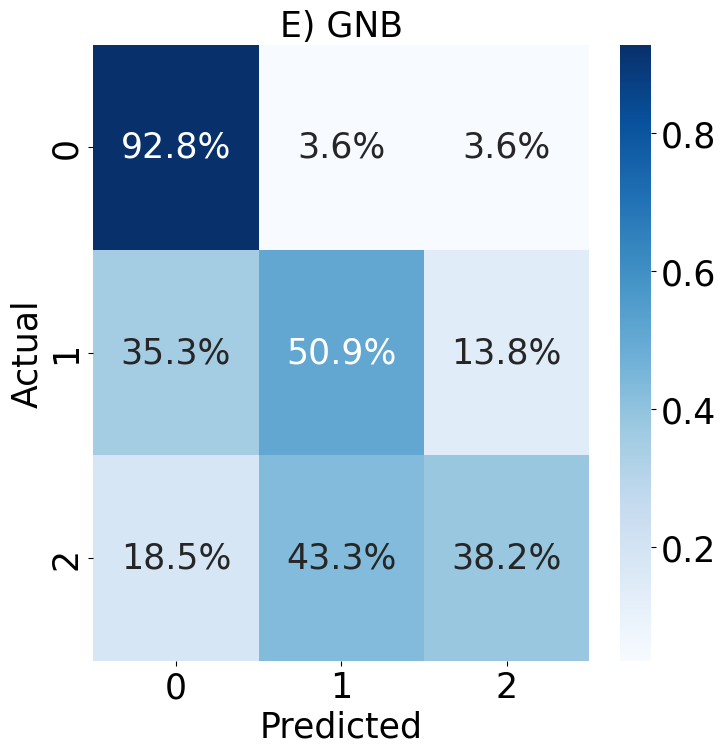

In [563]:
conf_matrix = confusion_matrix(y_test, y_pred)
conf_matrix_percentage = conf_matrix.astype('float') / conf_matrix.sum(axis=1)[:, np.newaxis]  # Calculate percentages

plt.figure(figsize=(8, 8))
heatmap=sns.heatmap(conf_matrix_percentage, annot=True, fmt='.1%', cmap='Blues', xticklabels=[0,1,2], yticklabels=[0,1,2],annot_kws={"size": 25})
plt.xticks(fontsize=25)
plt.yticks(fontsize=25)
plt.xlabel('Predicted',fontsize=25)
plt.ylabel('Actual',fontsize=25)
plt.title('E) GNB',fontsize=25)
cbar = heatmap.collections[0].colorbar
cbar.ax.tick_params(labelsize=25)
plt.show()

In [70]:
from sklearn.ensemble import VotingClassifier

# Ensamble

In [522]:
voting_clf = VotingClassifier(
    estimators=[('lr', model1), ('df', model2), ('rf', model3),('xgb', model4),('gnb', model5)],
    voting='hard'  # other options: 'soft' for soft voting
)

# Train the voting classifier
voting_clf.fit(X_train, y_train)

# Make predictions
y_pred = voting_clf.predict(X_test)

/Users/sayemahmed/anaconda3/lib/python3.11/site-packages/scipy/optimize/_linesearch.py:457: LineSearchWarning: The line search algorithm did not converge
  warn('The line search algorithm did not converge', LineSearchWarning)
/Users/sayemahmed/anaconda3/lib/python3.11/site-packages/scipy/optimize/_linesearch.py:306: LineSearchWarning: The line search algorithm did not converge
  warn('The line search algorithm did not converge', LineSearchWarning)


In [523]:
accuracy = accuracy_score(y_test, y_pred)
report = classification_report(y_test, y_pred)
print("Accuracy:", accuracy)
print("Classification Report:\n", report)

Accuracy: 0.762993762993763
Classification Report:
               precision    recall  f1-score   support

           0       0.80      0.88      0.84       111
           1       0.71      0.47      0.57       116
           2       0.76      0.84      0.80       254

    accuracy                           0.76       481
   macro avg       0.76      0.73      0.74       481
weighted avg       0.76      0.76      0.75       481



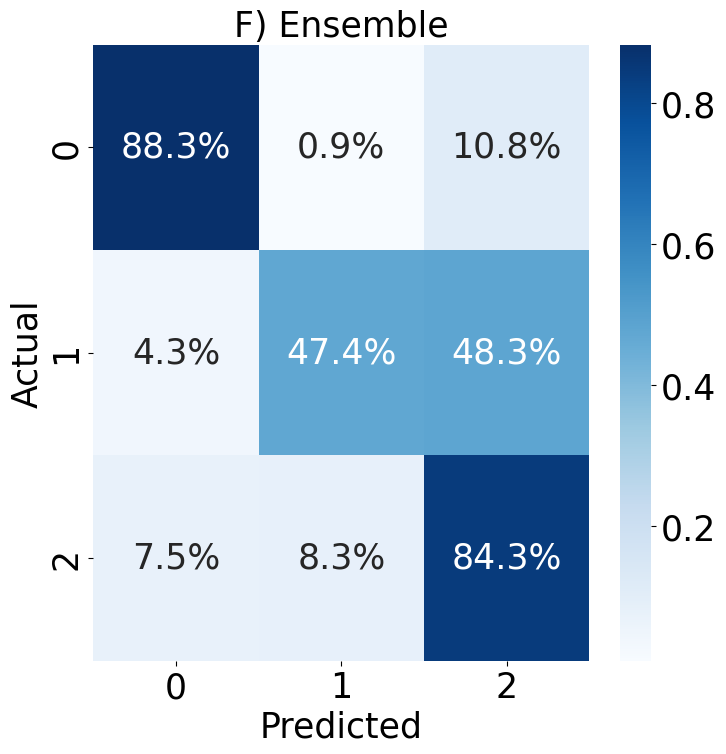

In [524]:
conf_matrix = confusion_matrix(y_test, y_pred)
conf_matrix_percentage = conf_matrix.astype('float') / conf_matrix.sum(axis=1)[:, np.newaxis]  # Calculate percentages

plt.figure(figsize=(8, 8))
heatmap=sns.heatmap(conf_matrix_percentage, annot=True, fmt='.1%', cmap='Blues', xticklabels=[0,1,2], yticklabels=[0,1,2],annot_kws={"size": 25})
plt.xticks(fontsize=25)
plt.yticks(fontsize=25)
plt.xlabel('Predicted',fontsize=25)
plt.ylabel('Actual',fontsize=25)
plt.title('F) Ensemble',fontsize=25)
cbar = heatmap.collections[0].colorbar
cbar.ax.tick_params(labelsize=25)
plt.show()

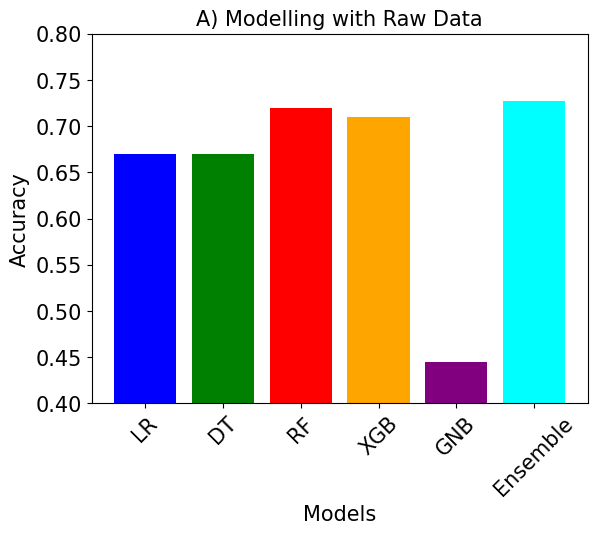

In [304]:
import matplotlib.pyplot as plt

# Sample data
categories = ['LR', 'DT', 'RF', 'XGB','GNB','Ensemble']
values = [0.67, 0.67, 0.72, 0.71,0.4453,0.7278]
colors = ['blue', 'green', 'red', 'orange', 'purple', 'cyan']
# Create bar plot
plt.bar(categories, values, color=colors)

# Adding title and labels
plt.title('A) Modelling with Raw Data',fontsize=15)
plt.xlabel('Models',fontsize=15)
plt.ylabel('Accuracy',fontsize=15)
plt.xticks(rotation=45, fontsize=15)
plt.yticks(fontsize=15)
plt.ylim(0.4, 0.8)
# Display the plot
plt.show()

In [564]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score

lr_pred = model1.predict(X_test)
df_pred = model2.predict(X_test)
rf_pred = model3.predict(X_test)
xgb_pred = model4.predict(X_test)
gnb_pred = model5.predict(X_test)

X_pred = np.column_stack((lr_pred, df_pred, rf_pred, xgb_pred, gnb_pred))

decision_tree_final = DecisionTreeClassifier(max_depth=5)
decision_tree_final.fit(X_pred, y_test)

final_prediction = decision_tree_final.predict(X_pred)

final_accuracy = accuracy_score(y_test, final_prediction)
print("Accuracy:", final_accuracy)

Accuracy: 0.7837837837837838


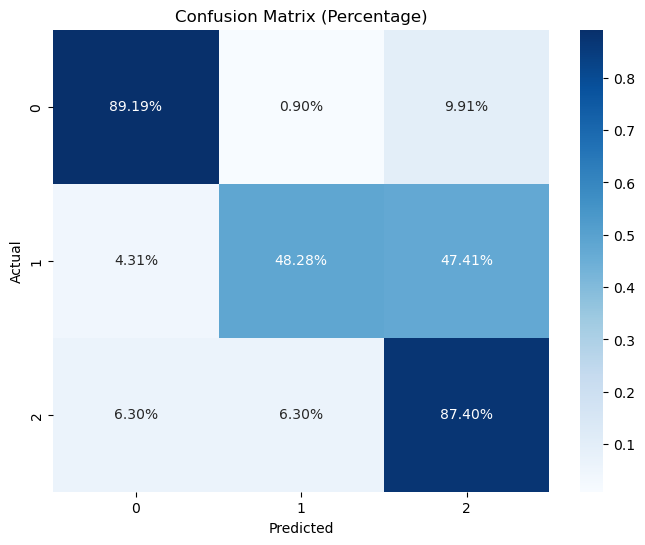

In [565]:
conf_matrix = confusion_matrix(y_test, final_prediction)
conf_matrix_percentage = conf_matrix.astype('float') / conf_matrix.sum(axis=1)[:, np.newaxis]  # Calculate percentages

plt.figure(figsize=(8, 6))
sns.heatmap(conf_matrix_percentage, annot=True, fmt='.2%', cmap='Blues', xticklabels=[0,1,2], yticklabels=[0,1,2])
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix (Percentage)')
plt.show()

In [144]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score

lr_train_pred = model1.predict(X_train)
df_train_pred = model2.predict(X_train)
rf_train_pred = model3.predict(X_train)
xgb_train_pred = model4.predict(X_train)
gnb_train_pred = model5.predict(X_train)


X_train_pred = np.column_stack((lr_train_pred, df_train_pred, rf_train_pred, xgb_train_pred, gnb_train_pred))

decision_tree_final = RandomForestClassifier(n_estimators=150,max_depth=3)
decision_tree_final.fit(X_train_pred, y_train)


lr_test_pred = model1.predict(X_test)
df_test_pred = model2.predict(X_test)
rf_test_pred = model3.predict(X_test)
xgb_test_pred = model4.predict(X_test)
gnb_test_pred = model5.predict(X_test)


X_test_pred = np.column_stack((lr_test_pred, df_test_pred, rf_test_pred, xgb_test_pred, gnb_test_pred))


final_prediction = decision_tree_final.predict(X_test_pred)

final_accuracy = accuracy_score(y_test, final_prediction)
print("Accuracy on Test Data:", final_accuracy)

Accuracy on Test Data: 0.7175257731958763


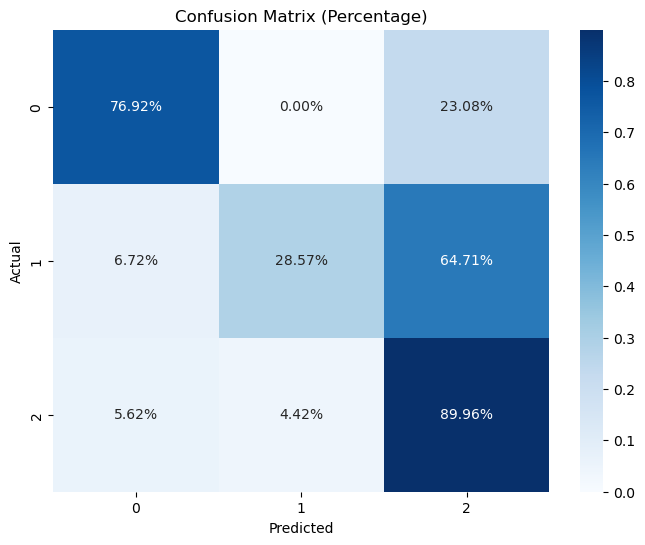

In [137]:
conf_matrix = confusion_matrix(y_test, final_prediction)
conf_matrix_percentage = conf_matrix.astype('float') / conf_matrix.sum(axis=1)[:, np.newaxis]  # Calculate percentages

plt.figure(figsize=(8, 6))
sns.heatmap(conf_matrix_percentage, annot=True, fmt='.2%', cmap='Blues', xticklabels=[0,1,2], yticklabels=[0,1,2])
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix (Percentage)')
plt.show()

In [112]:
from sklearn.preprocessing import MinMaxScaler, StandardScaler

In [74]:
X_train = StandardScaler().fit_transform(X_train)
X_test = StandardScaler().fit_transform(X_test)

In [75]:
X_test.shape

(481, 18)

In [76]:
X_train.shape

(1443, 18)

In [78]:
X_train=X_train.reshape(1443, 18,1)
X_test=X_test.reshape(481, 18,1)

In [79]:
y_train=y_train.to_numpy()
y_test=y_test.to_numpy()

In [80]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv1D, MaxPooling1D, Flatten, Dense
from tensorflow.keras.layers import BatchNormalization, Dropout

In [198]:
model = Sequential([
    Conv1D(32, kernel_size=3, activation='relu', input_shape=(18, 1)),
    MaxPooling1D(pool_size=2),
    Conv1D(16, kernel_size=3, activation='relu'),
    Flatten(),
    Dense(32, activation='relu'),  
    Dropout(0.5),
    Dense(24, activation='relu'),  
    Dropout(0.35),
    Dense(16, activation='relu'),  
    Dropout(0.35),
    Dense(3, activation='softmax')
])

In [199]:
model.summary()

Model: "sequential_16"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 conv1d_32 (Conv1D)          (None, 16, 32)            128       
                                                                 
 max_pooling1d_16 (MaxPooli  (None, 8, 32)             0         
 ng1D)                                                           
                                                                 
 conv1d_33 (Conv1D)          (None, 6, 16)             1552      
                                                                 
 flatten_16 (Flatten)        (None, 96)                0         
                                                                 
 dense_49 (Dense)            (None, 32)                3104      
                                                                 
 dropout_33 (Dropout)        (None, 32)                0         
                                                     

In [200]:
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras.callbacks import ModelCheckpoint, EarlyStopping, ReduceLROnPlateau, TerminateOnNaN,TensorBoard
# Add EarlyStopping callback
early_stop = EarlyStopping(monitor='val_loss', patience=10, restore_best_weights=True)

In [201]:
reduce_lr = ReduceLROnPlateau(monitor='val_loss', factor=0.2,
                              patience=5, min_lr=0.0001)

In [202]:
model.compile(optimizer='rmsprop', loss='sparse_categorical_crossentropy', metrics=['accuracy'])

In [203]:
tensorboard = TensorBoard(log_dir='./logs')

In [204]:
model.fit(
    X_train, y_train, epochs=70,
    batch_size=32, 
    validation_data=(X_test,y_test),
    callbacks=[reduce_lr,early_stop,tensorboard])

Epoch 1/70
46/46 [==============================] - 0s 2ms/step - loss: 1.0867 - accuracy: 0.3728 - val_loss: 1.0429 - val_accuracy: 0.4470 - lr: 0.0010
Epoch 2/70
46/46 [==============================] - 0s 1ms/step - loss: 1.0546 - accuracy: 0.3791 - val_loss: 1.0026 - val_accuracy: 0.4407 - lr: 0.0010
Epoch 3/70
46/46 [==============================] - 0s 1ms/step - loss: 1.0178 - accuracy: 0.3999 - val_loss: 0.9643 - val_accuracy: 0.4449 - lr: 0.0010
Epoch 4/70
46/46 [==============================] - 0s 1ms/step - loss: 1.0041 - accuracy: 0.4158 - val_loss: 0.9539 - val_accuracy: 0.5634 - lr: 0.0010
Epoch 5/70
46/46 [==============================] - 0s 1ms/step - loss: 0.9764 - accuracy: 0.4608 - val_loss: 0.9233 - val_accuracy: 0.5655 - lr: 0.0010
Epoch 6/70
46/46 [==============================] - 0s 1ms/step - loss: 0.9574 - accuracy: 0.4990 - val_loss: 0.9051 - val_accuracy: 0.5634 - lr: 0.0010
Epoch 7/70
46/46 [==============================] - 0s 1ms/step - loss: 0.9411 - a